### Chargement et selection des variables comportementales (X)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('primebet_players_clean.csv')

# Liste des 7 variables comportementales 
features_ml = [
    'bets_placed_total', #(volume de paris)
    'avg_bet_amount_eur', #(mise moyenne)
    'total_ggr', #(rentabilité pour Primebet)
    'days_since_last_activity', #(récence / inactivité)
    'gaming_sessions_per_week', #(fréquence de jeu)
    'casino_share_ratio', #(préférence Casino vs Sports)
    'loyalty_points' #(engagement fidélité)
]

X = df[features_ml].copy()

print(X.describe().T)

                            count         mean          std       min  \
bets_placed_total         10300.0    19.992611     4.451797      6.00   
avg_bet_amount_eur        10300.0   129.025011   148.572830   -706.88   
total_ggr                 10300.0   389.890604  1686.906505 -26652.49   
days_since_last_activity  10300.0   180.459592   102.189950      0.00   
gaming_sessions_per_week  10300.0     9.389950     5.789012      0.00   
casino_share_ratio        10300.0     0.090686     0.204761      0.00   
loyalty_points            10300.0  2507.151694  1426.790216      0.00   

                                25%      50%        75%       max  
bets_placed_total           17.0000    20.00    23.0000     39.30  
avg_bet_amount_eur          34.1075    81.63   174.9200    815.88  
total_ggr                    0.0000   123.57   745.0250  11970.34  
days_since_last_activity    93.3325   180.95   264.7750    377.56  
gaming_sessions_per_week     4.0800     9.00    14.3275     19.77  
casino_

### Correction et determination du nombre optimal de groupes 

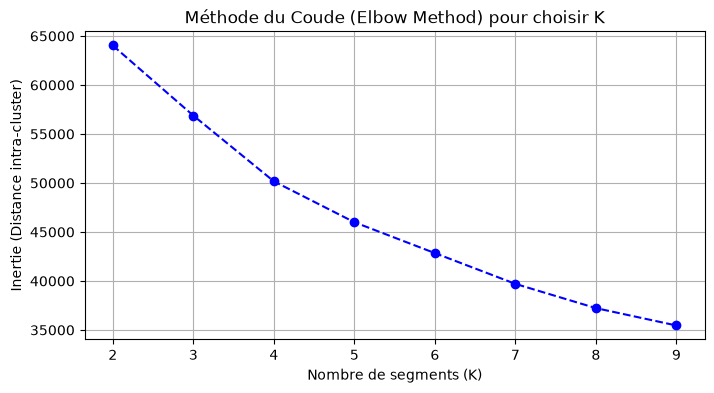

In [2]:
# CELLULE 2 : CORRECTION ANOMALIE & MÉTHODE DU COUDE (ELBOW)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Corriger les mises moyennes négatives (on ramène tout ce qui est < 0 à 0)
X['avg_bet_amount_eur'] = X['avg_bet_amount_eur'].clip(lower=0)

# 2. Standardiser les données (ramener les 7 colonnes à la même échelle)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Tester plusieurs nombres de groupes (K de 2 à 9)
inertias = []
K_range = range(2, 10)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

# 4. Afficher la courbe du Coude
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertias, marker='o', linestyle='--', color='b')
plt.title("Méthode du Coude (Elbow Method) pour choisir K")
plt.xlabel("Nombre de segments (K)")
plt.ylabel("Inertie (Distance intra-cluster)")
plt.xticks(K_range)
plt.grid(True)
plt.show()

In [3]:
# --- CELLULE 3 : PIPELINE DE PRODUCTION & ENTRAÎNEMENT (K=4) ---
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import joblib
import os

# 1. Construction du Pipeline industriel
ml_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(n_clusters=4, random_state=42, n_init=10))
])

# 2. Entraînement sur nos 7 variables propres (X) et prédiction des groupes
df['cluster'] = ml_pipeline.fit_predict(X)

# 3. Vérification de la taille de chaque groupe
print("Répartition des joueurs par segment (Cluster) :")
print(df['cluster'].value_counts().sort_index())

# 4. Sauvegarde du modèle prêt pour le Dashboard Streamlit et la production
os.makedirs('../models', exist_ok=True)
model_path = '../models/primebet_kmeans_pipeline.pkl'
joblib.dump(ml_pipeline, model_path)
print(f"\nModèle Pipeline sauvegardé avec succès -> {model_path}")

Répartition des joueurs par segment (Cluster) :
cluster
0    4353
1    4309
2     694
3     944
Name: count, dtype: int64

Modèle Pipeline sauvegardé avec succès -> ../models/primebet_kmeans_pipeline.pkl


--- PORTRAIT-ROBOT DES 4 SEGMENTS ---


,bets_placed_total,avg_bet_amount_eur,total_ggr,days_since_last_activity,gaming_sessions_per_week,casino_share_ratio,loyalty_points,nb_joueurs,churn_pct
cluster,,,,,,,,,
0,19.93,96.72,184.53,176.19,9.10,0.03,3720.68,4353,15.0
1,20.09,104.39,153.65,184.57,9.74,0.03,1253.37,4309,15.0
2,19.98,507.63,3300.46,187.10,8.99,0.06,2620.27,694,16.0
3,19.83,112.07,275.47,176.53,9.40,0.66,2551.17,944,14.0


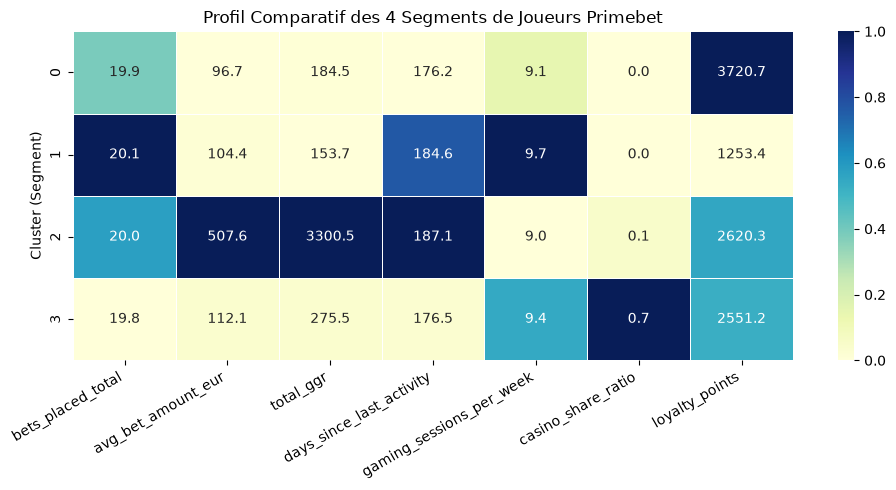

In [4]:
# --- CELLULE 4 : PROFILAGE & PORTRAIT-ROBOT DES 4 SEGMENTS ---

# 1. Calculer la moyenne des 7 variables + le taux de churn (en %) par cluster
colonnes_profil = features_ml + ['churn']
profil_clusters = df.groupby('cluster')[colonnes_profil].mean().round(2)

# Ajouter le nombre de joueurs par segment et convertir le churn en pourcentage
profil_clusters['nb_joueurs'] = df['cluster'].value_counts().sort_index()
profil_clusters['churn_pct'] = (profil_clusters['churn'] * 100).round(1)
profil_clusters = profil_clusters.drop(columns=['churn'])

# Afficher le tableau complet
print("--- PORTRAIT-ROBOT DES 4 SEGMENTS ---")
display(profil_clusters)

# 2. Visualisation rapide (Heatmap normalisée pour voir les points forts de chaque groupe)
plt.figure(figsize=(10, 5))
# On normalise par colonne (0 à 1) juste pour les couleurs de la heatmap
profil_norm = (profil_clusters[features_ml] - profil_clusters[features_ml].min()) / (
    profil_clusters[features_ml].max() - profil_clusters[features_ml].min()
)
sns.heatmap(profil_norm, annot=profil_clusters[features_ml], fmt=".1f", cmap="YlGnBu", linewidths=0.5)
plt.title("Profil Comparatif des 4 Segments de Joueurs Primebet")
plt.ylabel("Cluster (Segment)")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [5]:
# --- CELLULE 5 : ÉTIQUETAGE DES PERSONAS & EXPORT PRODUCTION ---
import json

# 1. Dictionnaire de correspondance Cluster -> Nom Marketing
persona_map = {
    0: "Parieurs Sportifs Fidèles",
    1: "Parieurs Sportifs Volatils (À Fidéliser)",
    2: "VIP / High-Rollers à Sécuriser",
    3: "Passionnés Casino & Crash Games"
}

df['persona'] = df['cluster'].map(persona_map)

# 2. Sauvegarder le dataset final segmenté pour le Dashboard (Phase 5)
os.makedirs('../data/processed', exist_ok=True)
segmented_path = '../data/processed/primebet_players_segmented.csv'
df.to_csv(segmented_path, index=False)
print(f"Dataset segmenté sauvegardé -> {segmented_path}")

# 3. Construire et sauvegarder le résumé JSON pour l'Agent IA (Phase 4)
resume_ia = {}
for cluster_id, persona_name in persona_map.items():
    sub = df[df['cluster'] == cluster_id]
    resume_ia[persona_name] = {
        "cluster_id": cluster_id,
        "nb_joueurs": int(len(sub)),
        "part_base_pct": round(len(sub) / len(df) * 100, 1),
        "mise_moyenne": round(float(sub['avg_bet_amount_eur'].mean()), 2),
        "ggr_moyen": round(float(sub['total_ggr'].mean()), 2),
        "jours_inactivite_moyen": round(float(sub['days_since_last_activity'].mean()), 1),
        "sessions_par_semaine": round(float(sub['gaming_sessions_per_week'].mean()), 1),
        "ratio_casino": round(float(sub['casino_share_ratio'].mean()), 2),
        "points_fidelite_moyen": round(float(sub['loyalty_points'].mean()), 1),
        "taux_churn_pct": round(float(sub['churn'].mean() * 100), 1),
        "jeu_prefere_top": sub['game_genre_preference'].mode()[0],
        "paiement_prefere_top": sub['payment_method'].mode()[0]
    }

json_path = '../data/processed/cluster_profiles.json'
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(resume_ia, f, indent=4, ensure_ascii=False)

print(f"Profils JSON pour l'IA sauvegardés -> {json_path}")
print("\nAperçu du JSON généré :")
print(json.dumps(resume_ia, indent=2, ensure_ascii=False))

Dataset segmenté sauvegardé -> ../data/processed/primebet_players_segmented.csv
Profils JSON pour l'IA sauvegardés -> ../data/processed/cluster_profiles.json

Aperçu du JSON généré :
{
  "Parieurs Sportifs Fidèles": {
    "cluster_id": 0,
    "nb_joueurs": 4353,
    "part_base_pct": 42.3,
    "mise_moyenne": 96.72,
    "ggr_moyen": 184.53,
    "jours_inactivite_moyen": 176.2,
    "sessions_par_semaine": 9.1,
    "ratio_casino": 0.03,
    "points_fidelite_moyen": 3720.7,
    "taux_churn_pct": 14.9,
    "jeu_prefere_top": "Live Roulette",
    "paiement_prefere_top": "Mobile Wallet / USSD"
  },
  "Parieurs Sportifs Volatils (À Fidéliser)": {
    "cluster_id": 1,
    "nb_joueurs": 4309,
    "part_base_pct": 41.8,
    "mise_moyenne": 104.39,
    "ggr_moyen": 153.65,
    "jours_inactivite_moyen": 184.6,
    "sessions_par_semaine": 9.7,
    "ratio_casino": 0.03,
    "points_fidelite_moyen": 1253.4,
    "taux_churn_pct": 14.6,
    "jeu_prefere_top": "Aviator (Crash Game)",
    "paiement_prefer